# Logistic Regression

### 1. Import libraries

In [1]:
import glob

import numpy as np
import pandas as pandas
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, PredefinedSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.base import clone
from sklearn.feature_selection import VarianceThreshold

#### 2. Data preprocessing

##### 2a. Import CSV files and combine into one dataframe

In [2]:
csv_folder = "../data/raw_data/*.csv"
file_paths = glob.glob(csv_folder)

print(f"Found {len(file_paths)} files")

dataframe_list = [pandas.read_csv(file) for file in file_paths]
dataframe_combined = pandas.concat(dataframe_list, ignore_index=True)
dataframe_combined = dataframe_combined.reset_index(drop=True)

Found 15 files


##### 2b. Overview of data

In [3]:
dataframe_combined.shape

(3385313, 85)

In [4]:
dataframe_combined.head()

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Attack Name,Label
0,34.173.20.6-192.168.137.234-443-58644-6,34.173.20.6,443,192.168.137.234,58644,6,14/09/2023 09:24:26 AM,14746364,6,0,...,0.0,0.0,0.0,0.0,14681116.0,0.000000,14681116.0,14681116.0,Benign Traffic,0
1,34.173.20.6-192.168.137.234-443-58646-6,34.173.20.6,443,192.168.137.234,58646,6,14/09/2023 09:24:41 AM,60102110,18,0,...,219123.0,0.0,219123.0,219123.0,14957706.0,190543.248665,15061923.0,14672051.0,Benign Traffic,0
2,52.40.210.103-192.168.137.40-18665-60378-6,52.40.210.103,18665,192.168.137.40,60378,6,14/09/2023 09:24:14 AM,90106769,9,0,...,582529.0,0.0,582529.0,582529.0,29841412.0,319090.538141,30049066.0,29473997.0,Benign Traffic,0
3,10.0.0.3-10.0.0.254-44505-1883-6,10.0.0.3,44505,10.0.0.254,1883,6,14/09/2023 09:24:15 AM,119998980,123,123,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,0
4,10.0.0.7-10.0.0.254-45727-1883-6,10.0.0.7,45727,10.0.0.254,1883,6,14/09/2023 09:24:15 AM,119998539,123,123,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,0


In [5]:
dataframe_combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 3385313 entries, 0 to 3385312
Data columns (total 85 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Flow ID                     str    
 1   Src IP                      str    
 2   Src Port                    int64  
 3   Dst IP                      str    
 4   Dst Port                    int64  
 5   Protocol                    int64  
 6   Timestamp                   str    
 7   Flow Duration               int64  
 8   Total Fwd Packet            int64  
 9   Total Bwd packets           int64  
 10  Total Length of Fwd Packet  float64
 11  Total Length of Bwd Packet  float64
 12  Fwd Packet Length Max       float64
 13  Fwd Packet Length Min       float64
 14  Fwd Packet Length Mean      float64
 15  Fwd Packet Length Std       float64
 16  Bwd Packet Length Max       float64
 17  Bwd Packet Length Min       float64
 18  Bwd Packet Length Mean      float64
 19  Bwd Packet Length Std       floa

In [6]:
dataframe_combined["Attack Name"].value_counts()

Attack Name
DoS TCP Flood               2106916
Recon Port Scan              485522
MQTT DDoS Publish Flood      413913
MQTT DoS Connect Flood       238031
Recon OS Scan                 85317
Benign Traffic                32620
Recon Vulnerability Scan       8321
DoS UDP Flood                  3115
DDoS UDP Flood                 2576
DDoS ICMP Flood                2552
MQTT Malformed                 2246
DoS ICMP Flood                 2107
MITM ARP Spoofing              1053
MQTT DoS Publish Flood          953
Recon Ping Sweep                 71
Name: count, dtype: int64

##### 2c. Drop Recon Ping Sweep due to its extremely low sample size

In [7]:
dataframe_combined = dataframe_combined[~dataframe_combined['Attack Name'].isin(['Recon Ping Sweep', 'MITM ARP Spoofing'])].copy()

##### 2c. Replace spaces in columns with "_"

In [8]:
dataframe_combined.columns = dataframe_combined.columns.str.replace(" ", "_")
dataframe_combined.columns.to_list()

['Flow_ID',
 'Src_IP',
 'Src_Port',
 'Dst_IP',
 'Dst_Port',
 'Protocol',
 'Timestamp',
 'Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'R

##### 2d. Drop problematic columns

In [9]:
dataframe_combined = dataframe_combined.drop(columns=["Flow_ID", "Src_IP", "Src_Port", "Dst_IP", "Dst_Port", "Protocol", "Timestamp", "Label"])
dataframe_combined.columns.to_list()

['Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'RST_Flag_Count',
 'PSH_Flag_Count',
 'ACK_Flag_Count',
 'URG_Flag_Count',
 'CWR_Flag_Cou

##### 2f. Drop rows with null values (currently unnecessary as no rows have null values)

In [10]:
dataframe_combined.dropna()

,Flow_Duration,Total_Fwd_Packet,Total_Bwd_packets,Total_Length_of_Fwd_Packet,Total_Length_of_Bwd_Packet,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,...,Fwd_Seg_Size_Min,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Attack_Name
0,14746364,6,0,63.0,0.0,39.0,0.0,10.500000,16.944025,0.0,...,32,0.0,0.0,0.0,0.0,14681116.0,0.000000,14681116.0,14681116.0,Benign Traffic
1,60102110,18,0,4135.0,0.0,1408.0,0.0,229.722222,490.460505,0.0,...,32,219123.0,0.0,219123.0,219123.0,14957706.0,190543.248665,15061923.0,14672051.0,Benign Traffic
2,90106769,9,0,1164.0,0.0,194.0,0.0,129.333333,97.000000,0.0,...,32,582529.0,0.0,582529.0,582529.0,29841412.0,319090.538141,30049066.0,29473997.0,Benign Traffic
3,119998980,123,123,2157.0,4.0,20.0,0.0,17.536585,2.309257,2.0,...,32,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic
4,119998539,123,123,5411.0,4.0,46.0,0.0,43.991870,5.699433,2.0,...,32,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3385308,210290,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan
3385309,202834,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan
3385310,208211,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan
3385311,132317,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan


### 3. Prepare data for model training

##### 3a. Sample smaller subset

In [26]:
def sample_or_take_all(group):
    sample_size = min(len(group), 6000)
    return group.sample(n=sample_size, random_state=42)

small_df = dataframe_combined.groupby('Attack_Name').apply(sample_or_take_all)
small_df = small_df.reset_index(level=0)

In [27]:
small_df.info()

<class 'pandas.DataFrame'>
Index: 55549 entries, 6528 to 3382716
Data columns (total 77 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Attack_Name                 55549 non-null  str    
 1   Flow_Duration               55549 non-null  int64  
 2   Total_Fwd_Packet            55549 non-null  int64  
 3   Total_Bwd_packets           55549 non-null  int64  
 4   Total_Length_of_Fwd_Packet  55549 non-null  float64
 5   Total_Length_of_Bwd_Packet  55549 non-null  float64
 6   Fwd_Packet_Length_Max       55549 non-null  float64
 7   Fwd_Packet_Length_Min       55549 non-null  float64
 8   Fwd_Packet_Length_Mean      55549 non-null  float64
 9   Fwd_Packet_Length_Std       55549 non-null  float64
 10  Bwd_Packet_Length_Max       55549 non-null  float64
 11  Bwd_Packet_Length_Min       55549 non-null  float64
 12  Bwd_Packet_Length_Mean      55549 non-null  float64
 13  Bwd_Packet_Length_Std       55549 non-null

##### 3b. Shuffle samples

In [28]:
small_df_rnd = small_df.sample(frac=1, random_state=42)
small_df_rnd = small_df_rnd.reset_index(drop=True)

In [29]:
small_df_rnd.info()

<class 'pandas.DataFrame'>
RangeIndex: 55549 entries, 0 to 55548
Data columns (total 77 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Attack_Name                 55549 non-null  str    
 1   Flow_Duration               55549 non-null  int64  
 2   Total_Fwd_Packet            55549 non-null  int64  
 3   Total_Bwd_packets           55549 non-null  int64  
 4   Total_Length_of_Fwd_Packet  55549 non-null  float64
 5   Total_Length_of_Bwd_Packet  55549 non-null  float64
 6   Fwd_Packet_Length_Max       55549 non-null  float64
 7   Fwd_Packet_Length_Min       55549 non-null  float64
 8   Fwd_Packet_Length_Mean      55549 non-null  float64
 9   Fwd_Packet_Length_Std       55549 non-null  float64
 10  Bwd_Packet_Length_Max       55549 non-null  float64
 11  Bwd_Packet_Length_Min       55549 non-null  float64
 12  Bwd_Packet_Length_Mean      55549 non-null  float64
 13  Bwd_Packet_Length_Std       55549 non-null

##### 3c. Separate targets and features

In [30]:
features = small_df_rnd.drop(columns=['Attack_Name'])
targets = small_df_rnd['Attack_Name']

In [31]:
targets.head

<bound method NDFrame.head of 0                 Recon Port Scan
1          MQTT DoS Connect Flood
2                   DoS UDP Flood
3          MQTT DoS Connect Flood
4                  DoS ICMP Flood
                   ...           
55544             Recon Port Scan
55545    Recon Vulnerability Scan
55546               Recon OS Scan
55547              Benign Traffic
55548               DoS TCP Flood
Name: Attack_Name, Length: 55549, dtype: str>

##### 3d. Scaling note

Logistic Regression is sensitive to feature scales. StandardScaler is included inside the model Pipeline below so it is fitted only on each training fold, avoiding data leakage.

In [32]:
# Scaling is performed inside the Pipeline in section 5e.
# Do not fit StandardScaler on the full dataset before splitting.

### 4. Split data into training and test

In [33]:
features_train, features_test, targets_train, targets_test = train_test_split(features, targets, test_size=0.2, random_state=12, shuffle=True)

### 5. Model Training - Hold-out Validation

##### 5a. Create helper evaluate functions

In [34]:
def evaluate(model, features_data, targets_data):
    prediction = model.predict(features_data)
    return {
        "Accuracy": accuracy_score(targets_data, prediction),
        "Precision": precision_score(targets_data, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1": f1_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1_macro": f1_score(targets_data, prediction, average="macro", zero_division=0),
    }

def evaluate_class_report(model, features_data, targets_data):
    prediction = model.predict(features_data)

    return classification_report(targets_data, prediction, output_dict=True, zero_division=0)



def plot_confusion_matrix(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm = confusion_matrix(targets_data, prediction)

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm

def plot_confusion_matrix_norm(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm_normalized = confusion_matrix(targets_data, prediction, normalize='true')

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm_normalized

##### 5b. Split for validation and gridsearchcv

In [35]:
# split for hold-out validation
X_train, X_val, Y_train, Y_val = train_test_split(features_train, targets_train, test_size=0.2, random_state=7, shuffle=True)

# split for GridSearchCV, stratify=Y_train maintains class proportions
X_train_param, X_val_param, Y_train_param, Y_val_param = train_test_split(X_train, Y_train, test_size=0.2, random_state=7, shuffle=True, stratify=Y_train)

##### 5c. Set parameter grid

In [50]:
# A deliberately compact search to keep runtime manageable.
# Tune regularization strength (C) and class weighting.
# Keep solver/penalty compatible and max_iter high enough to support convergence.
param_grid = [
    {
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"],
        "classifier__solver": ["lbfgs"],
        "classifier__penalty": ["l2"],
        "classifier__max_iter": [1000]
    },
    {
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"],
        "classifier__solver": ["saga"],
        "classifier__penalty": ["l1", "l2"],
        "classifier__max_iter": [1000]
    }
]

##### 5d. Combine training and validation data for the predefined split

This notebook uses a PredefinedSplit with one held-out validation fold. GridSearchCV tests each parameter combination against that same validation split; this is not k-fold cross-validation. The separate section 7 performs stratified k-fold evaluation.

In [51]:
X_combined = pandas.concat([X_train_param, X_val_param])
Y_combined = pandas.concat([Y_train_param, Y_val_param])

XY_fold = np.concatenate([
    np.full(len(X_train_param), -1),
    np.zeros(len(X_val_param))
])

holdout_cv = PredefinedSplit(XY_fold)

##### 5e. Create a Logistic Regression pipeline

In [52]:
model_holdout = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

##### 5f. GridSearchCV

In [53]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)


grid_search = GridSearchCV(
    estimator=model_holdout,
    param_grid=param_grid,
    scoring=scoring_param,
    cv=holdout_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit="f1_macro"
)

##### 5g. Run grid search

In [54]:
grid_search.fit(X_combined, Y_combined)

print("Best Parameters:")
print(grid_search.best_params_)
print("Best Validation Macro F1:")
print(grid_search.best_score_)

Fitting 1 folds for each of 36 candidates, totalling 36 fits


c:\Users\chris\OneDrive\Documents\a.School\Fall2026\MachineLearning\a.FinalProject\NetworkTrafficClassifier\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best Parameters:
{'classifier__C': 100, 'classifier__class_weight': None, 'classifier__max_iter': 1000, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}
Best Validation Macro F1:
0.5790585239449786


c:\Users\chris\OneDrive\Documents\a.School\Fall2026\MachineLearning\a.FinalProject\NetworkTrafficClassifier\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


##### 5h. Report all parameter combinations

In [55]:
# Compare parameter combinations, ranked by macro F1. 
grid_results = pandas.DataFrame(grid_search.cv_results_)

grid_results[
    [
        "rank_test_f1_macro",
        "mean_train_f1_macro",
        "mean_test_f1_macro",
        "mean_test_f1_weighted",
        "mean_test_accuracy",
        "mean_test_precision_weighted",
        "mean_test_recall_weighted",
        "params"
    ]
].sort_values("rank_test_f1_macro").head(10)

,rank_test_f1_macro,mean_train_f1_macro,mean_test_f1_macro,mean_test_f1_weighted,mean_test_accuracy,mean_test_precision_weighted,mean_test_recall_weighted,params
10,1,0.590921,0.579059,0.642848,0.694276,0.676654,0.694276,"{'classifier__C': 100, 'classifier__class_weig..."
11,2,0.584873,0.574906,0.635827,0.670651,0.672882,0.670651,"{'classifier__C': 100, 'classifier__class_weig..."
8,3,0.586202,0.573336,0.636213,0.691886,0.667371,0.691886,"{'classifier__C': 10, 'classifier__class_weigh..."
9,4,0.570181,0.561463,0.623635,0.657713,0.667046,0.657713,"{'classifier__C': 10, 'classifier__class_weigh..."
6,5,0.565908,0.557949,0.616587,0.677261,0.627196,0.677261,"{'classifier__C': 1, 'classifier__class_weight..."
7,6,0.531906,0.525627,0.575709,0.610603,0.593648,0.610603,"{'classifier__C': 1, 'classifier__class_weight..."
4,7,0.508700,0.496872,0.541058,0.599353,0.566681,0.599353,"{'classifier__C': 0.1, 'classifier__class_weig..."
26,8,0.500892,0.493744,0.536681,0.575728,0.569455,0.575728,"{'classifier__C': 1, 'classifier__class_weight..."
27,9,0.501103,0.492961,0.536202,0.575306,0.569340,0.575306,"{'classifier__C': 1, 'classifier__class_weight..."
5,10,0.501111,0.492852,0.536460,0.575728,0.569299,0.575728,"{'classifier__C': 0.1, 'classifier__class_weig..."


### 6. Train and evaluate baseline and optimized Logistic Regression models

##### 6a. Fit default baseline and Grid Search-selected model

In [86]:
# # Baseline: default Logistic Regression settings, with scaling.
# baseline_model = Pipeline(steps=[
#     ("scaler", StandardScaler()),
#     ("classifier", LogisticRegression())
# ])

# baseline_model.fit(X_train, Y_train)

# baseline_scores = pandas.DataFrame({
#     "Train": evaluate(baseline_model, X_train, Y_train),
#     "Validation": evaluate(baseline_model, X_val, Y_val),
# }).T

# print("Default Logistic Regression:")
# display(baseline_scores)

# # Optimized: use the parameters selected by GridSearchCV.
# best_model = clone(model_holdout).set_params(**grid_search.best_params_)
# best_model.fit(X_train, Y_train)

# holdout_scores = pandas.DataFrame({
#     "Train": evaluate(best_model, X_train, Y_train),
#     "Validation": evaluate(best_model, X_val, Y_val),
# }).T

# print("Grid Search Logistic Regression:")
# display(holdout_scores)

# print("Best parameters:")
# print(grid_search.best_params_)


# ========================================================================================================================================
# ========================================================================================================================================
# ========================================================================================================================================

# Optimized Parameter Model
best_model = LogisticRegression(
	max_iter=5000,
	C = 100,
	class_weight=None,
	penalty="l2",
	solver="lbfgs"
)

# Default Model
# best_model = LogisticRegression()

best_model.fit(X_train, Y_train)

holdout_scores = pandas.DataFrame({
    "Train": evaluate(best_model, X_train, Y_train),
    "Validation": evaluate(best_model, X_val, Y_val),
}).T

print("Grid Search Logistic Regression:")
display(holdout_scores)

print("Best parameters:")
print(grid_search.best_params_)

c:\Users\chris\OneDrive\Documents\a.School\Fall2026\MachineLearning\a.FinalProject\NetworkTrafficClassifier\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\chris\OneDrive\Documents\a.School\Fall2026\MachineLearning\a.FinalProject\NetworkTrafficClassifier\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://sci

Grid Search Logistic Regression:


,Accuracy,Precision,Recall,F1,F1_macro
Train,0.487637,0.417034,0.487637,0.398878,0.352925
Validation,0.488524,0.414505,0.488524,0.398965,0.357742


Best parameters:
{'classifier__C': 100, 'classifier__class_weight': None, 'classifier__max_iter': 1000, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}


##### 6b. Classification Reports

In [87]:
holdout_report_train = pandas.DataFrame(evaluate_class_report(best_model, X_train, Y_train)).T
holdout_report_train

,precision,recall,f1-score,support
Benign Traffic,0.432030,0.870380,0.577437,3896.000000
DDoS ICMP Flood,0.386667,0.089672,0.145582,1617.000000
DDoS UDP Flood,0.230088,0.015729,0.029445,1653.000000
DoS ICMP Flood,0.240283,0.051051,0.084211,1332.000000
DoS TCP Flood,0.762966,0.994980,0.863662,3785.000000
DoS UDP Flood,0.134511,0.146812,0.140392,2023.000000
MQTT DDoS Publish Flood,0.808889,0.605115,0.692319,3910.000000
MQTT DoS Connect Flood,0.695662,0.799738,0.744078,3810.000000
MQTT DoS Publish Flood,0.976804,0.614263,0.754229,617.000000
MQTT Malformed,0.562500,0.031601,0.059840,1424.000000


In [88]:
holdout_report_val = pandas.DataFrame(evaluate_class_report(best_model, X_val, Y_val)).T
holdout_report_val

,precision,recall,f1-score,support
Benign Traffic,0.435459,0.894569,0.585774,939.000000
DDoS ICMP Flood,0.427083,0.105670,0.169421,388.000000
DDoS UDP Flood,0.156250,0.011547,0.021505,433.000000
DoS ICMP Flood,0.257143,0.053097,0.088020,339.000000
DoS TCP Flood,0.772152,0.992879,0.868714,983.000000
DoS UDP Flood,0.141156,0.159615,0.149819,520.000000
MQTT DDoS Publish Flood,0.790230,0.603070,0.684080,912.000000
MQTT DoS Connect Flood,0.708182,0.799795,0.751205,974.000000
MQTT DoS Publish Flood,0.964706,0.616541,0.752294,133.000000
MQTT Malformed,0.642857,0.045570,0.085106,395.000000


##### 6c. Confusion Matrices

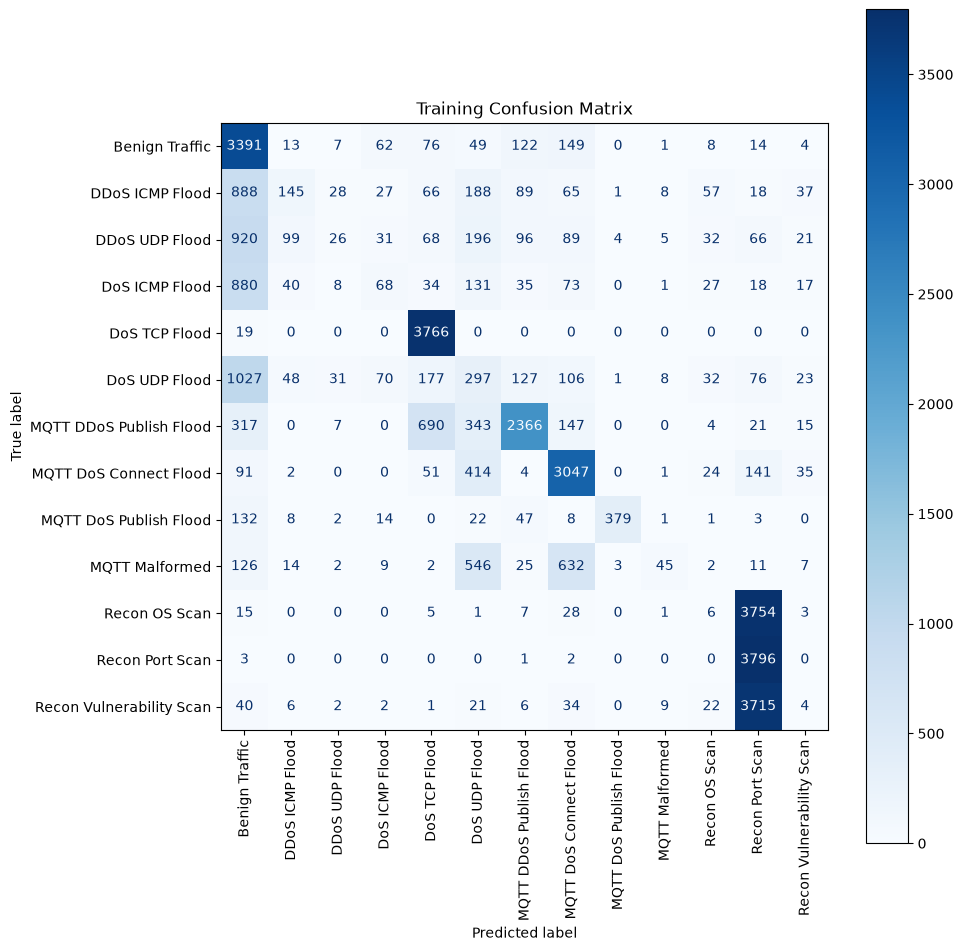

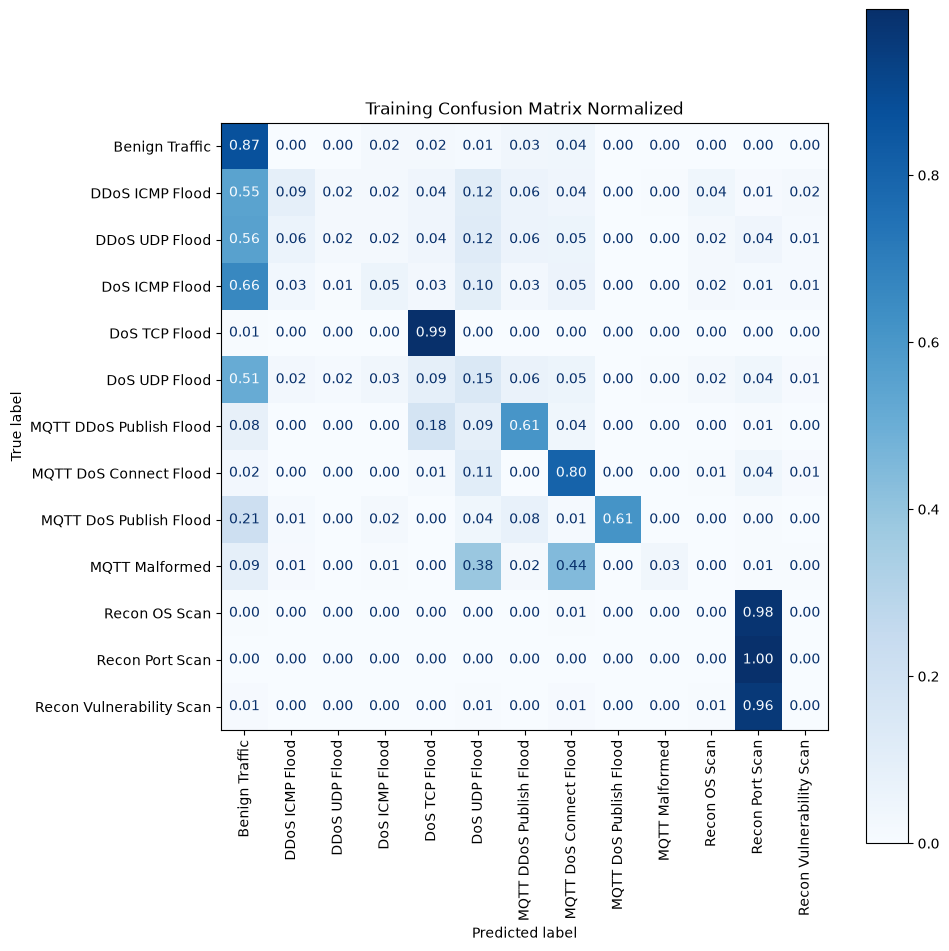

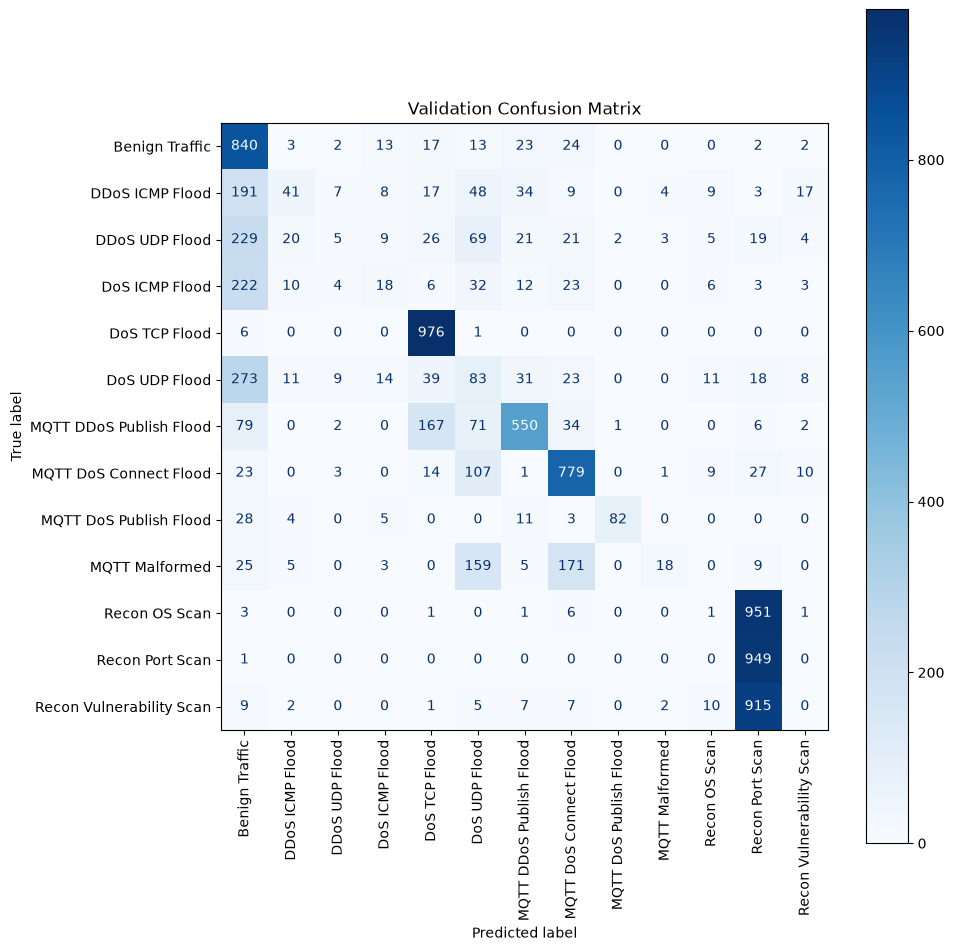

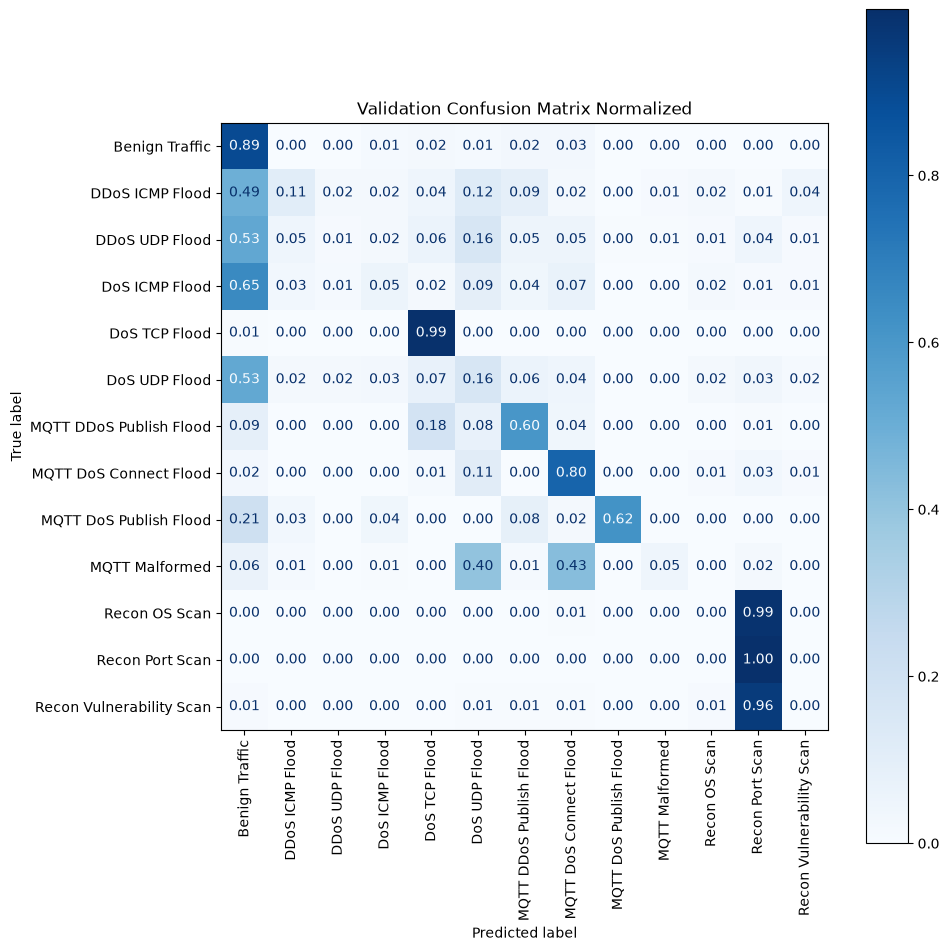

In [89]:
train_cm = plot_confusion_matrix(
    best_model,
    X_train,
    Y_train,
    title="Training Confusion Matrix"
)

train_cm_norm = plot_confusion_matrix_norm(
    best_model,
    X_train,
    Y_train,
    title="Training Confusion Matrix Normalized"
)

val_cm = plot_confusion_matrix(
    best_model,
    X_val,
    Y_val,
    title="Validation Confusion Matrix"
)

val_cm_norm = plot_confusion_matrix_norm(
    best_model,
    X_val,
    Y_val,
    title="Validation Confusion Matrix Normalized"
)

### 7. Model Training - Stratified K-fold Cross-validation

##### 7a. Set up Stratified K-fold validation

In [90]:
k = 10
strat_kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

model_cv = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

scoring = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro",
}

best_model_cv = clone(model_cv).set_params(**grid_search.best_params_)

cv_results = cross_validate(
    best_model_cv,
    X_train,
    Y_train,
    cv=strat_kfold,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

##### 7b. Dataframe stores fold results

In [91]:
fold_results = pandas.DataFrame({
    name: cv_results[f"{split}_{metric}"]
    for metric in scoring
    for split, name in [
        ("train", f"Train {metric}"),
        ("test", f"Test {metric}")
    ]
})

fold_results.index = range(1, k + 1)
fold_results.index.name = "Fold"

fold_results.round(4)

,Train accuracy,Test accuracy,Train precision_weighted,Test precision_weighted,Train recall_weighted,Test recall_weighted,Train f1_weighted,Test f1_weighted,Train f1_macro,Test f1_macro
Fold,,,,,,,,,,
1,0.7005,0.7019,0.6862,0.6868,0.7005,0.7019,0.6485,0.6489,0.5852,0.5827
2,0.6997,0.7024,0.6817,0.6909,0.6997,0.7024,0.6470,0.6502,0.5842,0.5892
3,0.7002,0.7021,0.6868,0.6841,0.7002,0.7021,0.6479,0.6489,0.5844,0.5857
4,0.7007,0.6923,0.6853,0.6663,0.7007,0.6923,0.6485,0.6384,0.5865,0.5724
5,0.7010,0.6970,0.6902,0.6757,0.7010,0.6970,0.6504,0.6456,0.5875,0.5824
6,0.7007,0.6934,0.6882,0.6743,0.7007,0.6934,0.6491,0.6411,0.5870,0.5706
7,0.7007,0.6993,0.6854,0.6729,0.7007,0.6993,0.6493,0.6465,0.5881,0.5825
8,0.7021,0.6970,0.6881,0.6853,0.7021,0.6970,0.6499,0.6456,0.5876,0.5820
9,0.7011,0.6970,0.6859,0.6842,0.7011,0.6970,0.6495,0.6439,0.5876,0.5825


##### 7c. Dataframe for summarizing results

In [92]:
cv_scores = pandas.DataFrame({
    metric: {
        "Mean": cv_results[f"test_{metric}"].mean(),
        "Std": cv_results[f"test_{metric}"].std()
    }
    for metric in scoring
}).T
cv_scores.round(4)

,Mean,Std
accuracy,0.6974,0.0038
precision_weighted,0.6794,0.0075
recall_weighted,0.6974,0.0038
f1_weighted,0.6446,0.0042
f1_macro,0.5796,0.0069


##### 7d. Training and Validation Comparison

In [93]:
cv_comparison = pandas.DataFrame({
    "Train Mean": [
        cv_results[f"train_{metric}"].mean()
        for metric in scoring
    ],
    "Train Std": [
        cv_results[f"train_{metric}"].std()
        for metric in scoring
    ],
    "Validation Mean": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Validation Std": [
        cv_results[f"test_{metric}"].std()
        for metric in scoring
    ],

}, index=scoring.keys())

cv_comparison["Mean Gap"] = (cv_comparison["Train Mean"] - cv_comparison["Validation Mean"])

cv_comparison.round(4)

,Train Mean,Train Std,Validation Mean,Validation Std,Mean Gap
accuracy,0.7009,0.0007,0.6974,0.0038,0.0034
precision_weighted,0.6865,0.0021,0.6794,0.0075,0.0071
recall_weighted,0.7009,0.0007,0.6974,0.0038,0.0034
f1_weighted,0.6490,0.0010,0.6446,0.0042,0.0044
f1_macro,0.5867,0.0016,0.5796,0.0069,0.0071
